# 11-视觉定位与简化手眼标定


## 1. 本篇范围与问题

第 10 篇介绍了如何从图像中识别颜色、形状并获得目标的像素位置。本篇继续回答一个实际问题：摄像头给出的是像素坐标，机械臂需要的是工作空间中的物理坐标，怎样把两者联系起来？

本篇依据 `opencv.pptx` 第 **12—15、19—20 页**整理。课件总标题为“数字图像基础与OpenCV入门”，本篇对应“最简易手眼标定”及案例七、八，内容包括：

- 用简化比例关系建立像素坐标到机器人平面坐标的“翻译器”；
- 相机垂直于工作平面时的物理前提；
- 通过已知尺寸物体计算 `mm/pixel` 比例尺；
- 用透视变换把倾斜视角转换为标准鸟瞰图；
- 用最小外接矩形测量物体中心、尺寸和旋转角度。

课件没有提供完整标定程序、相机内参、畸变参数或机械臂通信代码。**术语说明：**本篇的“手眼标定”沿用课程名称，内容是简化的图像到工作平面映射；它没有求解通用三维手眼标定中的相机与机器人之间的刚体变换。


## 2. 从像素位置到机器人位置

第 12 页提出的核心问题是：能不能通过简单的比例关系，让机器人找到摄像头看到的物体？

摄像头检测到物体后，会得到图像坐标，例如像素位置 `(u, v)`。机械臂控制需要工作平面上的物理位置，例如以机器人底座为参考的 `(X, Y)`，单位通常是毫米。

两种坐标表达的含义不同：

| 坐标 | 所在空间 | 示例 | 单位 |
|---|---|---|---|
| `(u, v)` | 图像平面 | `(450, 320)` | pixel |
| `(X, Y)` | 机器人工作平面 | `(152.5, 88.0)` | mm |

因此需要建立一个转换关系，把视觉结果翻译成机器人能够使用的物理坐标。

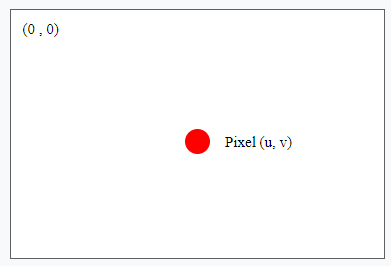

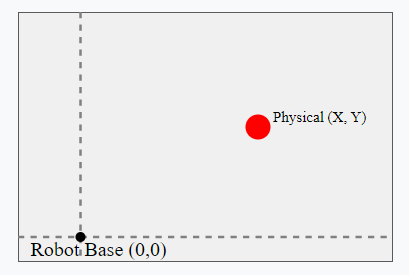

课件用以下示例说明输入和输出：

```text
输入：(u, v) = (450, 320)
输出：(X, Y) = (152.5, 88.0) mm
```

这里的数值用于说明坐标转换的形式。PPT 没有给出从 `(450, 320)` 推导出 `(152.5, 88.0)` 的具体标定参数，不能把它当作一组可直接复用的实测映射。


## 3. 简化场景的关键前提

课件第 14 页先限定一个容易处理的物理设置：**相机镜头垂直于工作平面**。

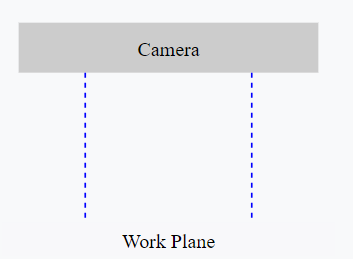

课件把这个简化场景比作地图：对于同一个工作平面，视野内的尺度近似一致，像素距离与真实距离能够用较简单的比例关系连接。

### 3.1 简化比例法的条件

“相机镜头垂直于工作平面”在这里指相机的**光轴沿工作平面的法向**，也就是正对工作平面。

**补充条件：**比例尺对应的是被测平面。被测点与标定参考物应处于同一平面，相机和工作平面的相对位置保持固定。物体高度明显变化时，即使相机朝下，投影尺度也会变化。

PPT 用“没有透视畸变、中心与边缘大小相同”描述理想设置。实际还需考虑镜头畸变，所以仅把相机摆正并不能保证全画面等比例。

### 3.2 通用场景的困难

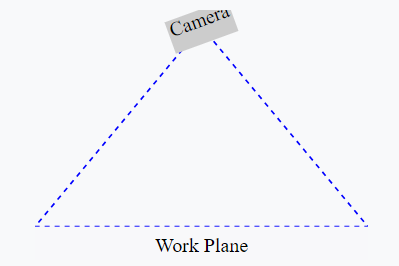

如果相机倾斜，近处物体看起来更大，远处物体看起来更小，工作平面在图像中会产生透视变形。此时，一个固定的 `mm/pixel` 比例通常不能准确覆盖整个画面。

**课件表述补充：**PPT 用“三维数学和旋转矩阵”说明通用场景更复杂。对于仍然位于同一平面的目标，可以使用后面案例七的平面透视变换；只有一个平面的映射不足以解决任意高度目标的三维定位。

> **适用边界：**本篇比例标定只针对课件设定的平面简化场景。不要把它直接用于相机倾斜、目标高度差明显或需要精确三维位姿的任务。


## 4. 用已知尺寸计算像素—物理比例尺

第 15 页把比例尺比作地图上的比例尺，核心问题是：**1 个像素代表多少毫米？**

### 4.1 课件中的操作步骤

1. 在相机视野中放置一个已知尺寸的物体，例如尺子或标定块。
2. 在图像上测量这个物体对应的像素长度。课件提到可以使用 OpenCV 鼠标回调函数或图像处理软件。
3. 用真实长度除以像素长度，得到比例尺。

公式为：

$$
\text{Scale (mm/pixel)}=
\frac{\text{真实长度 (mm)}}{\text{像素长度 (pixel)}}
$$

比例的单位是 `mm/pixel`。若两个像素点相差 `d` 个像素，简化场景下对应的物理距离可以估算为 `d × Scale` 毫米。

### 4.2 课件示例

课件给出的例子是：一个木块实际长度为 `10 mm`，在图像中测得为 `85 pixel`。

$$
\text{Scale}=\frac{10}{85}\approx 0.1176\text{ mm/pixel}
$$

这表示在该设置下，1 个像素约对应 `0.1176 mm`。

**补充说明：**这个比例随相机高度、焦距、图像分辨率或缩放、被测平面变化，不能脱离标定设置单独使用。测量的物理长度和像素长度必须对应同一条线段，像素长度应大于 `0`；计算中保留 `10/85` 的精度，可以减少提前取整带来的误差。


## 5. 简化映射中的坐标约定

**补充理解：**比例尺只确定距离换算，还没有确定机器人坐标的原点和轴方向。下面用一个简单关系解释课件中“坐标翻译器”还需要哪些信息，PPT 没有提供这些参数的完整求解过程。

第 09 篇已经说明图像坐标的约定：原点在左上角，`u` 向右增加，`v` 向下增加，数组访问使用 `image[v, u]`。

机器人工作平面则需要单独定义坐标系。例如，以机器人底座投影为原点时，`X`、`Y` 可以沿工作台的两个方向增加。图像与机器人坐标之间可能存在方向相同、方向相反或轴旋转的情况。

在两组坐标轴分别平行、允许方向相反，并可忽略透视与镜头畸变时，一个简化映射可以写成：

$$
X = X_0 + s_x(u-u_0),\qquad
Y = Y_0 + s_y(v-v_0)
$$

其中：

- `(u_0, v_0)` 是图像中的参考像素；
- `(X_0, Y_0)` 是机器人平面中对应的参考位置；
- `s_x`、`s_y` 是两个方向的物理比例，可能带正负号以表达轴方向。

若两组坐标轴之间还有平面内旋转，就需要考虑轴之间的耦合，不能只独立缩放 `u`、`v`。明显的透视与镜头畸变也超出了这个简式的适用范围。

> **易错点：**像素坐标写作 `(u, v)`，数组索引写作 `[v, u]`。把这两种顺序混用，会让目标在横纵方向上发生错位。


## 6. 案例七：从倾斜视角到“上帝视角”

课件第 19 页的案例功能是：用户通过鼠标点击矩形平面的四个顶点，把倾斜视角中的平面拉正，生成鸟瞰图，方便后续测量与定位。

> **术语说明：**PPT 将这个过程称为“去畸变”“生成无畸变的鸟瞰图”。这里具体指平面透视校正。它不会自动校正镜头的径向、切向畸变，也不会恢复被遮挡的信息。

### 6.1 透视变换的两组点

透视变换（Homography）可以把一个四边形映射到另一个四边形。课件区分两组点：

- **源四边形（Source）：**用户在倾斜图像中点击的四个顶点；
- **目标四边形（Destination）：**希望输出的标准矩形四个顶点。

课件举例把目标矩形设为宽 `400`、高 `300`，目标点为：

```text
(0, 0), (400, 0), (400, 300), (0, 300)
```

**补充条件：**四个源点和四个目标点必须一一对应，例如都按左上、右上、右下、左下排列。点应互不重复，且不能有三个点共线；选取的应是同一平面矩形的四个角。错误的对应关系会使结果翻转、扭曲或错位。

**像素边界说明：**上述坐标保留课件的几何矩形示例。若输出图像大小为 `400 × 300`，整数像素索引范围是横向 `0—399`、纵向 `0—299`。如果把目标四点定义成四角像素的中心，应使用 `(0, 0)、(399, 0)、(399, 299)、(0, 299)`；不要混淆几何边界与像素索引。

### 6.2 OpenCV 中的两个核心 API

| API | 作用 |
|---|---|
| `cv2.getPerspectiveTransform` | 接收两组四点，计算 3×3 透视变换矩阵 |
| `cv2.warpPerspective` | 使用变换矩阵把原图映射成目标视图 |

课件没有给出鼠标回调、点排序或完整调用代码。案例重点是理解：先取得源平面四点，再指定标准目标矩形，最后应用透视矩阵得到鸟瞰图。

透视变换建立的是一个平面到另一个平面的映射。它不能解决目标不在该平面时产生的高度误差。


## 7. 透视变换与比例标定的关系

**补充理解：**在相机倾斜的情况下，画面不同位置的尺度不同，直接使用一个全局 `mm/pixel` 比例会产生位置相关的误差。先把工作平面透视校正为标准矩形，可以在校正后的图像上建立平面比例关系。

一个常见的理解顺序是：

1. 选择工作平面的四个可见角点；
2. 把它们映射到规则的目标矩形；
3. 在校正后的平面上测量像素距离；
4. 用已知长度建立比例尺；
5. 再把目标中心或其他点转换为机器人坐标。

这段顺序用于解释课件中“透视变换”和“比例尺”的联系，PPT 没有提供对应的完整程序。

目标矩形的宽高比也有意义：若把真实长宽比不同的平面任意拉成 `400 × 300`，横纵方向可能出现不同缩放。只有两方向物理比例一致时，才适合用同一个比例尺换算长度，或直接把校正图中的角度解释为平面角度。校正后的比例尺也应在校正图上确定，不能直接沿用原图数值。


## 8. 案例八：测量物体姿态

课件第 20 页提出的功能是：用最小矩形框包围物体，计算其中心坐标、尺寸和旋转角度。

### 8.1 与轴对齐外接框的区别

`cv2.boundingRect` 只能生成与图像坐标轴平行的矩形。物体倾斜时，这个矩形会包含较多不属于物体的背景。

`cv2.minAreaRect` 会寻找能够包围轮廓的最小面积旋转矩形。这个矩形可以按物体方向旋转，通常更适合表达倾斜物体的姿态。

### 8.2 课件给出的输出量

`cv2.minAreaRect` 返回一个包含三类信息的结果：

| 信息 | 含义 |
|---|---|
| 中心坐标 `(x, y)` | 旋转矩形中心在图像中的位置，通常以像素为单位 |
| 尺寸 `(width, height)` | 旋转矩形两条边的长度，通常以像素为单位 |
| 旋转角度 | 矩形相对于图像坐标的方向 |

如果要把这个旋转矩形画出来，课件还要求调用 `cv2.boxPoints`，把旋转矩形结果转换成四个顶点坐标。

**返回结构说明：**课件描述的三类信息，在 Python 中可理解为 `((x, y), (width, height), angle)`。它是旋转矩形的参数，`cv2.boxPoints` 输出的才是四个角点。

### 8.3 二维姿态的含义

**补充说明：**矩形中心不一定等于不规则物体的质心，矩形方向也不一定代表物体唯一的语义朝向。这里测量的是图像中的二维姿态，没有由此得到深度或完整三维位姿。

OpenCV 的矩形角度与其宽高边定义有关，宽高交换时角度表达也可能变化。课件没有规定统一的角度方向与范围，使用时需要核对接口约定，不能直接把返回角度当作机械臂关节角。像素尺寸也要经过对应平面的比例换算，才具有毫米单位。
